In [1]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm import tqdm

In [2]:
DATASET_PATH = Path("../datasets/PlantVillage")

print(DATASET_PATH.exists())

True


In [3]:
classes = sorted([folder.name for folder in DATASET_PATH.iterdir() if folder.is_dir()])

print(f"Total Classes: {len(classes)}")
print()

for cls in classes:
    print(cls)

Total Classes: 15

Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato__Tomato_mosaic_virus
Tomato_healthy


In [4]:
image_counts = {}

total_images = 0

for cls in classes:
    count = len(list((DATASET_PATH / cls).glob("*")))
    image_counts[cls] = count
    total_images += count

print(f"Total Images: {total_images}")

Total Images: 20639


In [5]:
df = pd.DataFrame(
    image_counts.items(),
    columns=["Class", "Images"]
)

df = df.sort_values("Images", ascending=False)

df.head()

,Class,Images
12,Tomato__Tomato_YellowLeaf__Curl_Virus,3209
5,Tomato_Bacterial_spot,2127
7,Tomato_Late_blight,1909
9,Tomato_Septoria_leaf_spot,1771
10,Tomato_Spider_mites_Two_spotted_spider_mite,1676


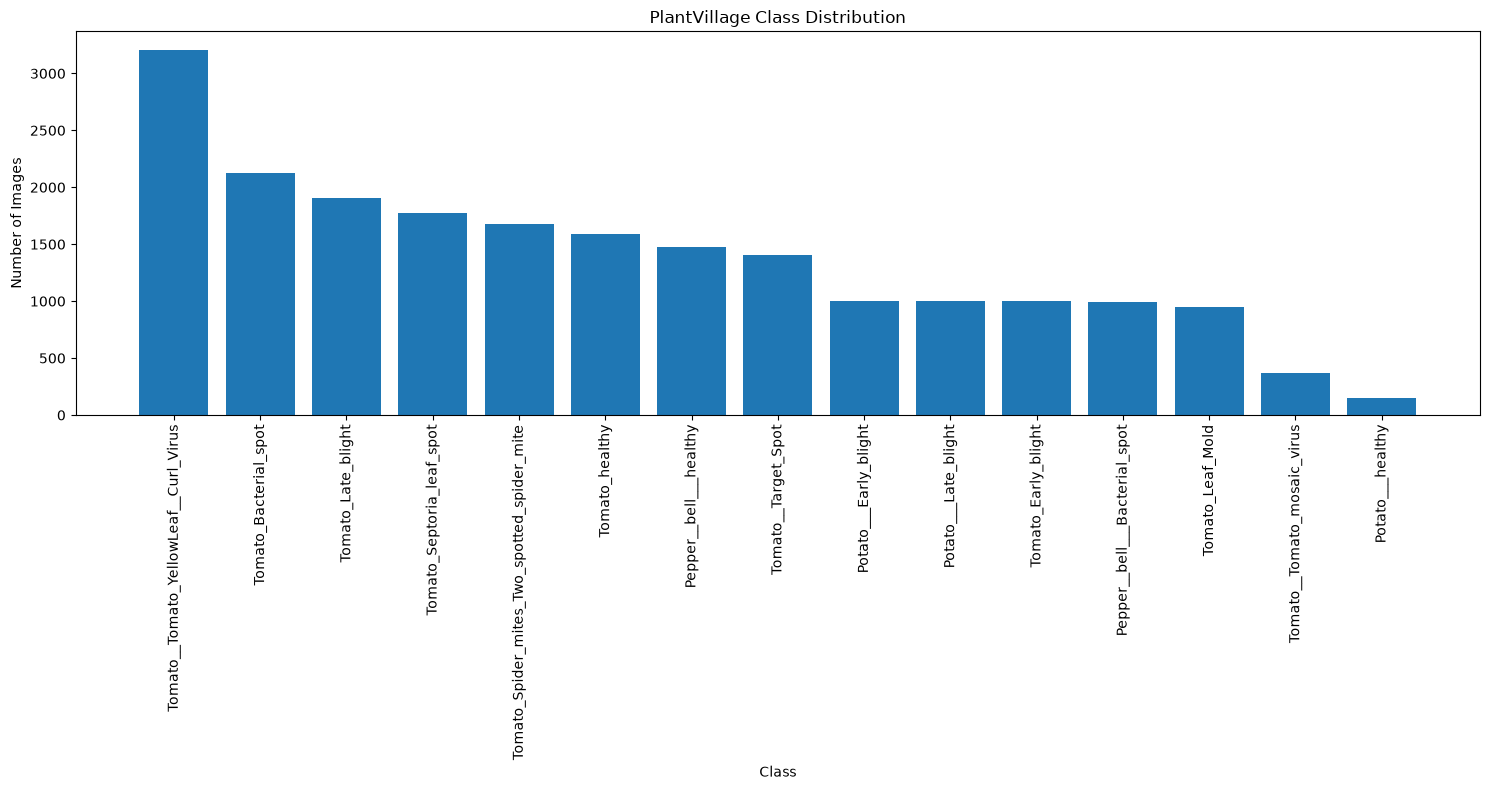

In [6]:
plt.figure(figsize=(15,8))

plt.bar(df["Class"], df["Images"])

plt.xticks(rotation=90)

plt.xlabel("Class")

plt.ylabel("Number of Images")

plt.title("PlantVillage Class Distribution")

plt.tight_layout()

plt.show()